**Knowledge Engineering**
**: Autonomous Trailer (Fuel Tanker) Knowledge Based Agent**

ICS 3202: Artificial Intelligence - Practical Exercise 4

189731 - KARANJA JOY WANGARI

172827 - AYIEKO AUDREY NYATICHI

189807 - AGWATA FELICIA NYABOKE

**Step 1: Identify the Task**

The task is to help our self-driving trailer (a fuel tanker) deliver fuel from Nairobi to Kisumu. The agent must:
*   plan the best route using the road map and Uniform Cost Search from Practical Exercise 3
*   decide what to do on the road based on what its sensors see (leaks, people, animals, vehicles, traffic lights, weighbridges, weather, tyre pressure, diesel level)

**Goal:** Deliver the fuel safely and on time meaning no accidents, spills or fires and using the shortest route and following traffic rules.

**Step 2: Assemble Relevant Knowledge**

The system needs to know:
*   The towns and the roads between them, with distances in km (directed graph from Exercise 3)
*   The GPS location of each town so as to get straight line distance and weather
*   Facts about the tanker which include : load, speed, diesel tank, tyre pressure
*   Facts about the roads which include : speed limits, weighbridges
*   Where the fuel stations and fuel depots are
*   The correct action for each situation the sensors can pick up
*   The current weather in a town

**APIs used:**
*   **Open-Meteo Weather API** - https://open-meteo.com/ We use it to get the current
    weather of a town using its latitude and longitude. The code is in the get_weather() function in Step 4
    and also uploaded to the repository as weather_api.py

Road distances were taken from our Practical Exercise 3 design. Town GPS coordinates were looked up on Google Maps.

**Step 3: Define the Vocabulary**
*   Predicates (represented in Python as dictionary keys, functions and rules):
    *   `Road(from_town, to_town, km)` - there is a road from one town to another and its distance
    *   `Location(town, latitude, longitude)` - where a town is
    *   `FuelStation(town)` - the truck can refuel in this town
    *   `FuelDepot(town)` - the tanker can load/offload fuel in this town
    *   `Weighbridge(from_town, to_town)` - there is a weighbridge on this road
    *   `SpeedLimit(from_town, to_town, kmh)` - speed limit on a road
    *   `Situation(name)` - something the sensors pick up
    *   `Action(situation, action)` - what to do in that situation
    *   `BestRoute(start, goal)` - the shortest route found by UCS
*   Constants:
    *   Towns: Nairobi, Nakuru, Kericho, Kisii, Eldoret, Kakamega, Kisumu
    *   Situations: Leak, Pedestrian, Vehicle close, Low tyre pressure, Animal, Red light, Weighbridge, Low diesel, Rain, Fog, Over speed limit, Vehicle far, Clear road
    *   Weather: Clear, Rain, Fog

**Step 4: Encode General Knowledge about the Domain**

This is the general knowledge the tanker knows before any trip.

In [2]:
import heapq
import math
import requests

# Road(from_town, to_town, km) - our directed graph from Exercise 3
graph = {
    'Nairobi': {'Nakuru': 161},
    'Nakuru': {'Kericho': 117, 'Eldoret': 156, 'Kisumu': 178},
    'Kericho': {'Kisumu': 84, 'Kisii': 104},
    'Kisii': {'Kisumu': 136},
    'Eldoret': {'Kisumu': 138, 'Kakamega': 106},
    'Kakamega': {'Kisumu': 81},
    'Kisumu': {}
}

# Location(town, latitude, longitude)
town_location = {
    'Nairobi': (-1.29, 36.82),
    'Nakuru': (-0.30, 36.07),
    'Kericho': (-0.37, 35.28),
    'Kisii': (-0.68, 34.77),
    'Eldoret': (0.51, 35.27),
    'Kakamega': (0.28, 34.75),
    'Kisumu': (-0.09, 34.77)
}

# facts about the tanker
tanker_facts = {
    "cargo": "petrol",
    "max_load_litres": 36000,
    "max_speed_kmh": 80,
    "diesel_tank_litres": 400,
    "diesel_per_km": 0.45,
    "min_tyre_pressure": 100
}

# SpeedLimit and Weighbridge facts about some roads
road_facts = {
    ('Nairobi', 'Nakuru'): {"speed_limit": 80, "weighbridge": True},
    ('Nakuru', 'Kisumu'): {"speed_limit": 80, "weighbridge": False},
    ('Nakuru', 'Kericho'): {"speed_limit": 60, "weighbridge": False},
    ('Nakuru', 'Eldoret'): {"speed_limit": 70, "weighbridge": True},
    ('Kericho', 'Kisumu'): {"speed_limit": 60, "weighbridge": False},
}

# FuelStation(town) and FuelDepot(town)
fuel_stations = ['Nairobi', 'Nakuru', 'Kericho', 'Eldoret', 'Kisumu']
fuel_depots = ['Nairobi', 'Nakuru', 'Eldoret', 'Kisumu']


# they are in order of importance, the first one that matches is used
rules = {
    "Leak": "Stop, close the tank shut-off valve, sound the alarm and call the control office.",
    "Pedestrian": "Emergency brake - person on the road.",
    "Vehicle close": "Brake hard - vehicle too close.",
    "Low tyre pressure": "Slow down, put on indicators and pull over.",
    "Animal": "Slow down and hoot.",
    "Red light": "Stop at the traffic light.",
    "Weighbridge": "Stop at the weighbridge.",
    "Low diesel": "Go to the nearest fuel station.",
    "Rain": "Reduce speed and turn on lights.",
    "Fog": "Reduce speed and turn on fog lights.",
    "Over speed limit": "Slow down - above the speed limit.",
    "Vehicle far": "Keep a safe distance behind the vehicle.",
    "Clear road": "Continue driving.",
}

In [3]:
# distance measure from Exercise 3: path cost = add up the road distances
def path_cost(path):
    total = 0
    for i in range(len(path) - 1):
        total = total + graph[path[i]][path[i+1]]
    return total

# second distance measure: straight line distance using GPS
def straight_line_distance(town1, town2):
    lat1, lon1 = town_location[town1]
    lat2, lon2 = town_location[town2]
    R = 6371
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat/2)**2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon/2)**2
    return round(R * 2 * math.atan2(math.sqrt(a), math.sqrt(1-a)))

# BestRoute(start, goal) - our Uniform Cost Search from Exercise 3
def uniform_cost_search(start, goal, show=True):
    pq = [(0, start, [start])]
    visited = []
    if show:
        print("Starting UCS from", start, "to", goal, "\n")
    while pq:
        cost, node, path = heapq.heappop(pq)
        if show:
            print("Visiting:", node, "| Cost:", cost, "| Path:", " -> ".join(path))
        if node == goal:
            if show:
                print("\nGoal reached!")
            return cost, path
        if node not in visited:
            visited.append(node)
            for neighbor, distance in graph[node].items():
                if neighbor not in visited:
                    heapq.heappush(pq, (cost + distance, neighbor, path + [neighbor]))
    return float('inf'), []

# all routes from start to goal (the branches of our search tree)
def all_routes(start, goal, path=None):
    if path is None:
        path = [start]
    if start == goal:
        return [path]
    routes = []
    for next_town in graph[start]:
        if next_town not in path:
            routes = routes + all_routes(next_town, goal, path + [next_town])
    routes.sort(key=path_cost)
    return routes

# API: get the current weather of a town from Open-Meteo
def get_weather(town):
    lat, lon = town_location[town]
    url = f"https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}&current_weather=true"
    try:
        data = requests.get(url, timeout=5).json()
        code = data["current_weather"]["weathercode"]
        if code in [45, 48]:
            return "Fog"
        elif code >= 51:
            return "Rain"
        else:
            return "Clear"
    except:
        return "Clear"

print("General knowledge loaded:", len(graph), "towns,", len(rules), "rules")
print("Weather in Nairobi right now:", get_weather("Nairobi"))

General knowledge loaded: 7 towns, 13 rules
Weather in Nairobi right now: Rain


**The inference part (TELL and ASK)**

The sensors give a percept which is what the tanker sees. sense() turns the percept into situations,
then ask() checks the rules in order and returns the action for the most important situation.

In [5]:
def sense(percept):
    # turn what the sensors see into a list of situations
    situations = []
    if percept.get("leak") == True:
        situations.append("Leak")
    obstacle = percept.get("obstacle", "none").capitalize()
    if obstacle == "Vehicle":
        if percept.get("obstacle_distance", 0) < 50:
            situations.append("Vehicle close")
        else:
            situations.append("Vehicle far")
    elif obstacle != "None":
        situations.append(obstacle)
    if percept.get("tyre_pressure", 110) < tanker_facts["min_tyre_pressure"]:
        situations.append("Low tyre pressure")
    if percept.get("traffic_light") == "red":
        situations.append("Red light")
    if percept.get("weighbridge") == True:
        situations.append("Weighbridge")
    if percept.get("diesel_percent", 100) < 15:
        situations.append("Low diesel")
    if percept.get("weather") in ["Rain", "Fog"]:
        situations.append(percept["weather"])
    if percept.get("speed", 0) > percept.get("speed_limit", 80):
        situations.append("Over speed limit")
    if situations == []:
        situations.append("Clear road")
    return situations


class TankerAgent:
    def __init__(self):
        self.kb = []

    def tell(self, percept):

        self.kb = sense(percept)

    def ask(self):

        for situation in rules:
            if situation in self.kb:
                return situation, rules[situation]

        return self.kb[0], "Unknown situation - slow down and proceed with caution."

agent = TankerAgent()

**Step 5: Add New Facts to the Knowledge Base**

The knowledge base can grow. We can add new rules which are situations and actions, new roads and new towns.

In [6]:
def show_kb():
    print("\n--- Current Knowledge Base ---")
    print("Roads:")
    for town, roads in graph.items():
        for to_town, km in roads.items():
            print(f"  {town:9} ➜ {to_town:9} {km} km")
    print("Rules:")
    for situation, action in rules.items():
        print(f"  {situation:18} ➜ {action}")
    print("Fuel stations:", fuel_stations)
    print("Fuel depots:", fuel_depots)
    print("-------------------------------")

def add_new_fact(situation, action):
    """Add a new rule directly to the KB (without user input)."""
    situation = situation.capitalize()
    rules[situation] = action
    # keep 'Clear road' as the last rule
    rules["Clear road"] = rules.pop("Clear road")
    print(f"Added fact: '{situation}' ➜ '{action}'")

def add_new_road(from_town, to_town, km, lat=None, lon=None):
    """Add a new road (and a new town if we don't know it yet)."""
    for town in [from_town, to_town]:
        if town not in graph:
            graph[town] = {}
    graph[from_town][to_town] = km
    if lat is not None:
        town_location[to_town] = (lat, lon)
    print(f"Added road: {from_town} ➜ {to_town} = {km} km")

# Examples of adding facts
add_new_fact("Pothole", "Slow down and steer around the pothole.")
add_new_fact("Fire", "Stop, switch off the engine, sound the alarm and call the control office.")
add_new_road("Kisumu", "Busia", 115, 0.46, 34.11)
fuel_stations.append("Busia")
print("Added fact: Busia has a fuel station")

def add_fact():
    """Add new knowledge (facts) to the KB using input."""
    new_situation = input("Enter a new situation the tanker can see: ").capitalize()
    new_action = input(f"What should the tanker do when it sees {new_situation}? ")
    add_new_fact(new_situation, new_action)

add_fact()

# View updated KB
show_kb()

Added fact: 'Pothole' ➜ 'Slow down and steer around the pothole.'
Added fact: 'Fire' ➜ 'Stop, switch off the engine, sound the alarm and call the control office.'
Added road: Kisumu ➜ Busia = 115 km
Added fact: Busia has a fuel station
Enter a new situation the tanker can see: Diesel spill
What should the tanker do when it sees Diesel spill? Stop and call the control office
Added fact: 'Diesel spill' ➜ 'Stop and call the control office'

--- Current Knowledge Base ---
Roads:
  Nairobi   ➜ Nakuru    161 km
  Nakuru    ➜ Kericho   117 km
  Nakuru    ➜ Eldoret   156 km
  Nakuru    ➜ Kisumu    178 km
  Kericho   ➜ Kisumu    84 km
  Kericho   ➜ Kisii     104 km
  Kisii     ➜ Kisumu    136 km
  Eldoret   ➜ Kisumu    138 km
  Eldoret   ➜ Kakamega  106 km
  Kakamega  ➜ Kisumu    81 km
  Kisumu    ➜ Busia     115 km
Rules:
  Leak               ➜ Stop, close the tank shut-off valve, sound the alarm and call the control office.
  Pedestrian         ➜ Emergency brake - person on the road.
  Vehicl

**Steps 6 & 7: Encode Specific Problem Instance (Facts) & Pose Queries and Get Answers**

Step 6: the specific trip (start, destination, load) and what the sensors see right now.

Step 7: the agent uses the knowledge base to answer meaning it plans the route and decides the action.

In [7]:
# Step 6: the specific trip entered on the keyboard (sensor from our PEAS)
start = input("Enter the start town: ").strip().title()
goal = input("Enter the destination town: ").strip().title()
load = float(input("Enter the load in litres: "))

# Step 7: the agent queries the knowledge base to plan the trip
def plan_trip(start, goal, load):
    print(f"\n=== Trip Plan: {start} to {goal} ({load} litres of {tanker_facts['cargo']}) ===")
    if start not in graph or goal not in graph:
        print("I don't know that town.")
        return []
    if load > tanker_facts["max_load_litres"]:
        print("Cannot go: the tank can only carry", tanker_facts["max_load_litres"], "litres.")
        return []
    cost, route = uniform_cost_search(start, goal)
    if route == []:
        print(f"There is no road from {start} to {goal} in my map.")
        return []
    diesel = round(cost * tanker_facts["diesel_per_km"])
    print("\nBest route:", " -> ".join(route))
    print("Distance:", cost, "km")
    print("Time (approx):", round(cost / tanker_facts["max_speed_kmh"], 1), "hours")
    print("Diesel needed:", diesel, "litres")
    if diesel > tanker_facts["diesel_tank_litres"]:
        print("Diesel tank is not enough. Refuel at:", [t for t in route if t in fuel_stations])
    else:
        print("Diesel tank is enough for the trip.")
    for i in range(len(route) - 1):
        info = road_facts.get((route[i], route[i+1]), {})
        if info.get("weighbridge"):
            print(f"Note: weighbridge between {route[i]} and {route[i+1]}")
    if goal not in fuel_depots:
        print(f"Warning: {goal} has no fuel depot to offload at.")
    return route

route = plan_trip(start, goal, load)

Enter the start town: Nairobi
Enter the destination town: Kisumu
Enter the load in litres: 30000

=== Trip Plan: Nairobi to Kisumu (30000.0 litres of petrol) ===
Starting UCS from Nairobi to Kisumu 

Visiting: Nairobi | Cost: 0 | Path: Nairobi
Visiting: Nakuru | Cost: 161 | Path: Nairobi -> Nakuru
Visiting: Kericho | Cost: 278 | Path: Nairobi -> Nakuru -> Kericho
Visiting: Eldoret | Cost: 317 | Path: Nairobi -> Nakuru -> Eldoret
Visiting: Kisumu | Cost: 339 | Path: Nairobi -> Nakuru -> Kisumu

Goal reached!

Best route: Nairobi -> Nakuru -> Kisumu
Distance: 339 km
Time (approx): 4.2 hours
Diesel needed: 153 litres
Diesel tank is enough for the trip.
Note: weighbridge between Nairobi and Nakuru


In [8]:
# Step 6: what the sensors see right now
print("Enter what the sensors see right now:")
current_percept = {
    "leak": input("Leak detected? (y/n): ").lower() == "y",
    "obstacle": input("Obstacle (none/vehicle/pedestrian/animal/pothole/...): ").strip().lower(),
    "obstacle_distance": float(input("Distance to obstacle in metres (0 if none): ")),
    "traffic_light": input("Traffic light (none/red/green): ").strip().lower(),
    "speed": float(input("Current speed km/h: ")),
    "speed_limit": 80,
    "tyre_pressure": 110,
    "weighbridge": False,
    "diesel_percent": 60,
    "weather": get_weather(start) if start in town_location else "Clear",
}

# Step 7: TELL the agent and ASK what to do
agent.tell(current_percept)
situation, action = agent.ask()

print("\n=== Tanker Decision System ===")
print("Situations seen:", agent.kb)
print("Most important:", situation)
print("Agent Decision:", action)

Enter what the sensors see right now:
Leak detected? (y/n): n
Obstacle (none/vehicle/pedestrian/animal/pothole/...): pothole
Distance to obstacle in metres (0 if none): 30
Traffic light (none/red/green): none
Current speed km/h: 60

=== Tanker Decision System ===
Situations seen: ['Pothole', 'Rain']
Most important: Rain
Agent Decision: Reduce speed and turn on lights.


In [9]:
# Step 7 (continued): drive the planned route and at each road the agent is TOLD what it sees and ASKED what to do
def drive(route):
    road_events = [
        {"obstacle": "animal", "obstacle_distance": 30, "speed": 70},
        {"obstacle": "vehicle", "obstacle_distance": 20, "speed": 75},
        {"obstacle": "none", "obstacle_distance": 0, "speed": 90, "tyre_pressure": 95},
        {"obstacle": "pothole", "obstacle_distance": 40, "speed": 60},
    ]
    diesel = 100
    for i in range(len(route) - 1):
        town, next_town = route[i], route[i+1]
        info = road_facts.get((town, next_town), {"speed_limit": 80, "weighbridge": False})
        weather = get_weather(town)
        print(f"\n--- {town} ➜ {next_town} | weather: {weather} | diesel: {diesel}% ---")

        if info["weighbridge"]:
            agent.tell({"weighbridge": True, "speed": 30, "diesel_percent": diesel, "weather": weather})
            print("  Weighbridge ahead ➜", agent.ask()[1])

        percept = dict(road_events[i % len(road_events)])
        percept["diesel_percent"] = diesel
        percept["weather"] = weather
        percept["speed_limit"] = info["speed_limit"]
        agent.tell(percept)
        print("  Sees:", agent.kb, "➜", agent.ask()[1])

        diesel = round(diesel - graph[town][next_town] * tanker_facts["diesel_per_km"] / tanker_facts["diesel_tank_litres"] * 100)
    print(f"\nArrived at {route[-1]} - offloading at the fuel depot.")

if route:
    drive(route)


--- Nairobi ➜ Nakuru | weather: Rain | diesel: 100% ---
  Weighbridge ahead ➜ Stop at the weighbridge.
  Sees: ['Animal', 'Rain'] ➜ Slow down and hoot.

--- Nakuru ➜ Kisumu | weather: Clear | diesel: 82% ---
  Sees: ['Vehicle close'] ➜ Brake hard - vehicle too close.

Arrived at Kisumu - offloading at the fuel depot.


**Step 8: Querying the knowledge base**

In [10]:
# ask questions to get answers from the knowledge base
print("Q: What is the best route from Nairobi to Kisumu?")
cost, best = uniform_cost_search("Nairobi", "Kisumu", show=False)
print("A:", " -> ".join(best), "=", cost, "km\n")

print("Q: What are all the routes from Nairobi to Kisumu? (backup routes)")
for r in all_routes("Nairobi", "Kisumu"):
    print("  ", " - ".join(r), "=", path_cost(r), "km")

print("\nQ: How far is Nakuru from Kisumu in a straight line?")
print("A:", straight_line_distance("Nakuru", "Kisumu"), "km")

print("\nQ: Is there a fuel station in Kisii?")
print("A:", "Yes" if "Kisii" in fuel_stations else "No")

print("\nQ: Is there a weighbridge between Nairobi and Nakuru?")
print("A:", "Yes" if road_facts.get(("Nairobi", "Nakuru"), {}).get("weighbridge") else "No")

print("\nQ: What is the weather in Kisumu now? (from the API)")
print("A:", get_weather("Kisumu"))

print("\nQ: What should the tanker do if there is a leak and a pedestrian at the same time?")
agent.tell({"leak": True, "obstacle": "pedestrian", "obstacle_distance": 10})
print("A:", agent.ask()[1])

print("\nQ: What should the tanker do if it sees a pothole? (new fact from Step 5)")
agent.tell({"obstacle": "pothole", "obstacle_distance": 30})
print("A:", agent.ask()[1])

print("\nQ: Can the tanker now go from Nairobi to Busia? (new road from Step 5)")
cost, r = uniform_cost_search("Nairobi", "Busia", show=False)
print("A:", " -> ".join(r), "=", cost, "km")

Q: What is the best route from Nairobi to Kisumu?
A: Nairobi -> Nakuru -> Kisumu = 339 km

Q: What are all the routes from Nairobi to Kisumu? (backup routes)
   Nairobi - Nakuru - Kisumu = 339 km
   Nairobi - Nakuru - Kericho - Kisumu = 362 km
   Nairobi - Nakuru - Eldoret - Kisumu = 455 km
   Nairobi - Nakuru - Eldoret - Kakamega - Kisumu = 504 km
   Nairobi - Nakuru - Kericho - Kisii - Kisumu = 518 km

Q: How far is Nakuru from Kisumu in a straight line?
A: 146 km

Q: Is there a fuel station in Kisii?
A: No

Q: Is there a weighbridge between Nairobi and Nakuru?
A: Yes

Q: What is the weather in Kisumu now? (from the API)
A: Clear

Q: What should the tanker do if there is a leak and a pedestrian at the same time?
A: Stop, close the tank shut-off valve, sound the alarm and call the control office.

Q: What should the tanker do if it sees a pothole? (new fact from Step 5)
A: Slow down and steer around the pothole.

Q: Can the tanker now go from Nairobi to Busia? (new road from Step 5)
A

**Step 9: Debugging the Knowledge Base**

We test normal, new and faulty inputs to see how the agent reacts.

In [11]:
# test the rules with different sensor readings
test_cases = [
    {"obstacle": "pedestrian", "obstacle_distance": 10},
    {"obstacle": "vehicle", "obstacle_distance": 20},
    {"obstacle": "vehicle", "obstacle_distance": 200},
    {"obstacle": "animal", "obstacle_distance": 30},
    {"traffic_light": "red"},
    {"tyre_pressure": 80},
    {"diesel_percent": 10},
    {"weather": "Fog"},
    {"speed": 100, "speed_limit": 80},
    {"obstacle": "elephant", "obstacle_distance": 50},
    {"obstacle": "teal", "obstacle_distance": 5},
    {},
]

print("--- Debugging the rules ---")
for test in test_cases:
    agent.tell(test)
    situation, action = agent.ask()
    print(f"{str(test):45} -> {situation:18} -> {action}")

--- Debugging the rules ---
{'obstacle': 'pedestrian', 'obstacle_distance': 10} -> Pedestrian         -> Emergency brake - person on the road.
{'obstacle': 'vehicle', 'obstacle_distance': 20} -> Vehicle close      -> Brake hard - vehicle too close.
{'obstacle': 'vehicle', 'obstacle_distance': 200} -> Vehicle far        -> Keep a safe distance behind the vehicle.
{'obstacle': 'animal', 'obstacle_distance': 30} -> Animal             -> Slow down and hoot.
{'traffic_light': 'red'}                      -> Red light          -> Stop at the traffic light.
{'tyre_pressure': 80}                         -> Low tyre pressure  -> Slow down, put on indicators and pull over.
{'diesel_percent': 10}                        -> Low diesel         -> Go to the nearest fuel station.
{'weather': 'Fog'}                            -> Fog                -> Reduce speed and turn on fog lights.
{'speed': 100, 'speed_limit': 80}             -> Over speed limit   -> Slow down - above the speed limit.
{'obstacle':

In [12]:
# test the route planning with good and bad inputs
route_tests = [
    ("Nairobi", "Kisumu", 30000),
    ("Nakuru", "Kisii", 20000),
    ("Kisumu", "Nairobi", 30000),
    ("Nairobi", "Mombasa", 30000),
    ("Nairobi", "Kisumu", 50000),
]

print("--- Debugging the route planning ---")
for s, g, l in route_tests:
    if s not in graph or g not in graph:
        print(f"{s} -> {g}: Unknown town")
    elif l > tanker_facts["max_load_litres"]:
        print(f"{s} -> {g}: Load too big ({l} litres)")
    else:
        cost, r = uniform_cost_search(s, g, show=False)
        if r == []:
            print(f"{s} -> {g}: No route found")
        else:
            print(f"{s} -> {g}: {' -> '.join(r)} = {cost} km")

--- Debugging the route planning ---
Nairobi -> Kisumu: Nairobi -> Nakuru -> Kisumu = 339 km
Nakuru -> Kisii: Nakuru -> Kericho -> Kisii = 221 km
Kisumu -> Nairobi: No route found
Nairobi -> Mombasa: Unknown town
Nairobi -> Kisumu: Load too big (50000 litres)


From the tests above:
*   An **elephant** is not in the KB so the agent gives the default "Unknown situation" answer. This is safe but
    not specific, so we add a rule for it below.
*   **Kisumu to Nairobi** has no route because our graph only has roads going towards Kisumu. To fix this we
    would add the return roads.
*   **Mombasa** is not in our map, so the agent cannot plan that trip.

In [13]:
# fixing the problems we found
add_new_fact("Elephant", "Stop and wait for the elephant to cross. Do not hoot.")
add_new_road("Kisumu", "Nakuru", 178)
add_new_road("Nakuru", "Nairobi", 161)

# test again
agent.tell({"obstacle": "elephant", "obstacle_distance": 50})
print("\nElephant ->", agent.ask()[1])
cost, r = uniform_cost_search("Kisumu", "Nairobi", show=False)
print("Kisumu -> Nairobi:", " -> ".join(r), "=", cost, "km")

Added fact: 'Elephant' ➜ 'Stop and wait for the elephant to cross. Do not hoot.'
Added road: Kisumu ➜ Nakuru = 178 km
Added road: Nakuru ➜ Nairobi = 161 km

Elephant -> Stop and wait for the elephant to cross. Do not hoot.
Kisumu -> Nairobi: Kisumu -> Nakuru -> Nairobi = 339 km


**Step 10: Add final reflection here (challenges or recommended improvements)**

**Challenges**
*   The tanker can see many things at the same time such as a leak and a pedestrian. We had to put the rules in
    order of importance so the most dangerous situation is handled first.
*   Our graph from Exercise 3 is directed and only goes towards Kisumu, so the tanker could not plan the trip
    back. We found this while debugging and added return roads.
*   The agent only knows the situations in its rules. Anything new like an elephant gets a general "proceed
    with caution" answer until we add a rule for it.
*   The weather API needs internet. If it fails the agent assumes the weather is clear, which may not be safe.
*   Road distances, speed limits and weighbridge locations had to be typed in by hand, so they can be outdated.

**Recommended improvements**
*   Use a maps API such as Google Maps or OpenStreetMap to get road distances and live traffic instead of typing them.
*   Add more towns and roads, and road conditions like roadworks or closed roads, so the agent can re-plan the route.
*   Let the control office send new rules and facts to the tanker while it is driving.
*   Use A* search with the straight line distance as the heuristic so the agent searches fewer towns on a bigger map.
*   Save the knowledge base to a file so new facts are not lost when the notebook restarts.

**Evidence of Group Work**

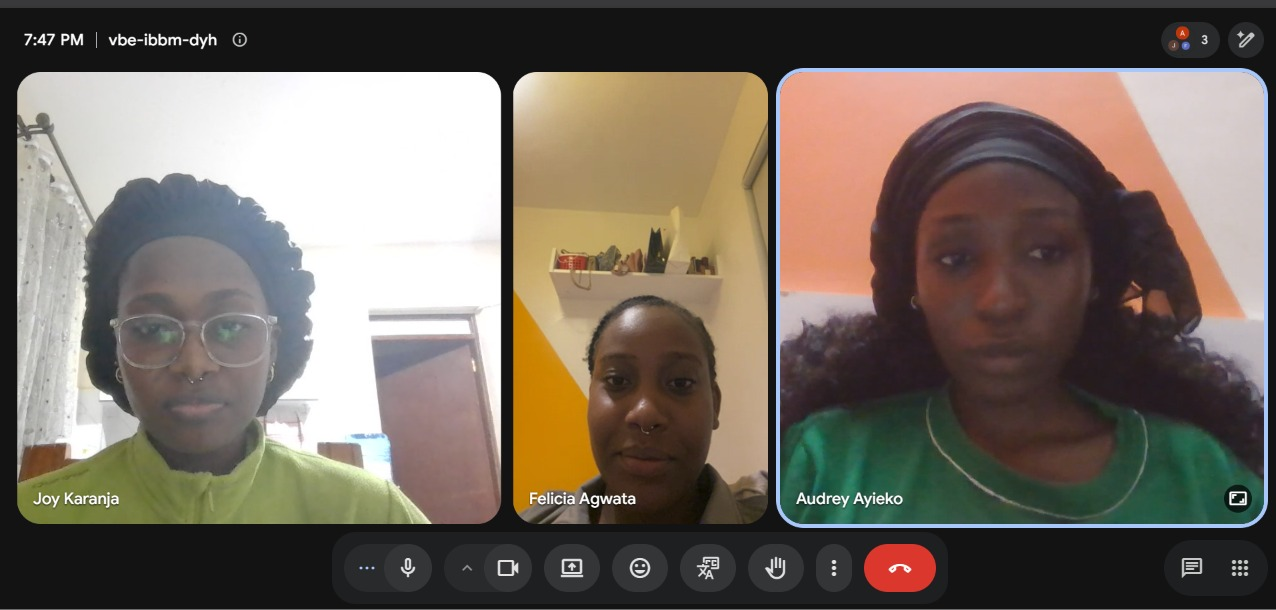